The idea for this notebook is to train an MNIST classification model using only numpy - calculating the gradient by hand to understand the fundamental building blocks of training a Neural Network. 

- data ingesting
- gradient descent
- batches, epocs and iterations
- training loops
- etc.

In [110]:
import numpy as np
import matplotlib.pyplot as plt
import gzip
import hashlib
import struct
from pathlib import Path

# Let's grab the data first

In [111]:
# Mirror of Yann LeCun's original archive (the original host now blocks scripted downloads).
BASE_URL = "https://storage.googleapis.com/cvdf-datasets/mnist/"

DATA_DIR = Path(__file__).parent / "data"

#DATA_DIR = Path("your data dir")

FILES = {
    "train_images": "train-images-idx3-ubyte.gz",
    "train_labels": "train-labels-idx1-ubyte.gz",
    "test_images": "t10k-images-idx3-ubyte.gz",
    "test_labels": "t10k-labels-idx1-ubyte.gz",
}

# sha256 of each gzip file, so a truncated download is caught instead of
# turning into a confusing parse error later.
CHECKSUMS = {
    "train-images-idx3-ubyte.gz": "440fcabf73cc546fa21475e81ea370265605f56be210a4024d2ca8f203523609",
    "train-labels-idx1-ubyte.gz": "3552534a0a558bbed6aed32b30c495cca23d567ec52cac8be1a0730e8010255c",
    "t10k-images-idx3-ubyte.gz": "8d422c7b0a1c1c79245a5bcf07fe86e33eeafee792b84584aec276f5a2dbc4e6",
    "t10k-labels-idx1-ubyte.gz": "f7ae60f92e00ec6debd23a6088c31dbd2371eca3ffa0defaefb259924204aec6",
}


def _download(filename):
    """Fetch one .gz into data/, skipping the download if it is already there."""
    DATA_DIR.mkdir(exist_ok=True)
    path = DATA_DIR / filename

    if not path.exists():
        url = BASE_URL + filename
        print(f"downloading {filename} ...")
        urllib.request.urlretrieve(url, path)

    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    if digest != CHECKSUMS[filename]:
        path.unlink()
        raise RuntimeError(f"{filename} failed its checksum; re-run to download again")

    return path


def _read_idx(path):
    """Parse an IDX file into a numpy array.

    Header is big-endian: a 4-byte magic number whose last byte is the number
    of dimensions, then one 4-byte length per dimension.
    """
    with gzip.open(path, "rb") as f:
        magic = f.read(4)
        n_dims = magic[3]
        shape = struct.unpack(f">{n_dims}I", f.read(4 * n_dims)) # type: ignore
        return np.frombuffer(f.read(), dtype=np.uint8).reshape(shape)


def load_mnist(flatten=True, normalize=True, one_hot=True, validation_size=5000, seed=0):
    """Download MNIST (once) and return it as numpy arrays ready for training.

    flatten          28x28 images -> length-784 vectors, the shape a dense
                     layer expects.
    normalize        pixels from 0..255 uint8 -> 0..1 float32. Keeps the first
                     layer's inputs small so gradients behave.
    one_hot          labels 0..9 -> length-10 vectors, to compare against a
                     10-unit softmax output.
    validation_size  images held out of the 60k training set to check progress
                     without touching the test set.

    Returns a dict of X_train/y_train, X_val/y_val, X_test/y_test.
    """
    paths = {key: _download(name) for key, name in FILES.items()}

    X_train_full = _read_idx(paths["train_images"])
    y_train_full = _read_idx(paths["train_labels"])
    X_test = _read_idx(paths["test_images"])
    y_test = _read_idx(paths["test_labels"])

    def prep_images(images):
        images = images.reshape(len(images), -1) if flatten else images
        if normalize:
            images = images.astype(np.float32) / 255.0
        return images

    def prep_labels(labels):
        if not one_hot:
            return labels.astype(np.int64)
        encoded = np.zeros((len(labels), 10), dtype=np.float32)
        encoded[np.arange(len(labels)), labels] = 1.0
        return encoded

    # Shuffle before splitting: MNIST's training file is not ordered by digit,
    # but shuffling makes the split independent of file order regardless.

    rng = np.random.default_rng(seed)
    order = rng.permutation(len(X_train_full))
    
    X_train_full, y_train_full = X_train_full[order], y_train_full[order]

    X_val, y_val = X_train_full[:validation_size], y_train_full[:validation_size]
    X_train, y_train = X_train_full[validation_size:], y_train_full[validation_size:]

    return {

        # IMPORTANT:
        # transpose so each column is one example, as a dense layer expects.

        "X_train": prep_images(X_train).T,
        "y_train": prep_labels(y_train).T,
        "X_val": prep_images(X_val).T,
        "y_val": prep_labels(y_val).T,
        "X_test": prep_images(X_test).T,
        "y_test": prep_labels(y_test).T,
    }


def batches(X, Y, batch_size=64, shuffle=True, rng=None):
    """Yield (X_batch, Y_batch) column slices - one epoch's worth."""
    m = X.shape[1]
    rng = rng or np.random.default_rng()
    idx = rng.permutation(m) if shuffle else np.arange(m)
    for start in range(0, m, batch_size):
        chunk = idx[start:start + batch_size]
        yield X[:, chunk], Y[:, chunk]


def show(image, label=None):
    """Print one digit as ASCII art, to sanity-check what you actually loaded."""
    pixels = np.asarray(image).reshape(28, 28)
    if pixels.max() <= 1.0:
        pixels = pixels * 255
    ramp = " .:-=+*#%@"
    for row in pixels:
        print("".join(ramp[int(p) * (len(ramp) - 1) // 255] for p in row))
    if label is not None:
        label = int(np.argmax(label)) if np.ndim(label) else int(label)
        print(f"label: {label}")


data = load_mnist()
for name, array in data.items():
    print(f"{name:9} {array.shape!s:14} {array.dtype}")
print()
# show(data["X_train"][0], data["y_train"][0])


X_train   (784, 55000)   float32
y_train   (10, 55000)    float32
X_val     (784, 5000)    float32
y_val     (10, 5000)     float32
X_test    (784, 10000)   float32
y_test    (10, 10000)    float32



In [112]:
# NOTE : training data is arranged in columns
#
# so each column is one training example. 
#
# This is the convention used in many deep learning texts, including the original MNIST paper.

X_train = data["X_train"] # (784, 55000)
Y_train = data["y_train"] # (10, 55000)
X_dev = data["X_val"]     # (784, 5000)
Y_dev = data["y_val"]     # (10, 5000)


print("X_train - shape is", X_train.shape)
print("Y_train - shape is", Y_train.shape)
print("X_dev - shape is", X_dev.shape)
print("Y_dev - shape is", Y_dev.shape, "\n")

print("One column of X_train - shape is", X_train[:, 0].shape )
print("One column of Y_train - shape is", Y_train[:, 0].shape)
print("One column of X_dev - shape is", X_dev[:, 0].shape)
print("One column of Y_dev - shape is", Y_dev[:, 0].shape)


# X_train.shape = (784, 55000)

n = X_train.shape[0] # number of features (784)

m = X_train.shape[1] # number of training examples (55000)


X_train - shape is (784, 55000)
Y_train - shape is (10, 55000)
X_dev - shape is (784, 5000)
Y_dev - shape is (10, 5000) 

One column of X_train - shape is (784,)
One column of Y_train - shape is (10,)
One column of X_dev - shape is (784,)
One column of Y_dev - shape is (10,)


## initialize the network

- utilizes He initialization which works well with a ReLU activation

In [113]:
def init_params(hidden: int = 128) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
   
    """784-hidden-10 network with He initialisation (suited to ReLU)."""
   
    rng = np.random.default_rng(seed=4098273752)

    # 128 hidden neurons, each with a weight for every one of the 784 input pixels
    W1 = rng.standard_normal((hidden, 784)) * np.sqrt(2 / 784)   # (128, 784)

    # one bias per hidden neuron - can be zero - biases don't need randomness
    b1 = np.zeros((hidden, 1))                                    # (128, 1)

    # 128 hidden neurons (digits 0-9), each with a weight for every one of the 10 hidden neurons
    W2 = rng.standard_normal((10, hidden)) * np.sqrt(2 / hidden)  # (10, 128)
   
    # one bias per output neuron
    b2 = np.zeros((10, 1))                                        # (10, 1)

    return W1, b1, W2, b2


In [114]:
def ReLU(Z):
    return np.maximum(0, Z) # element-wise 

def deriv_ReLU(Z):
    return Z > 0 # boolean gets coerced to 1 or 0 ;)

def softmax(Z):
    return np.exp(Z) / np.sum(np.exp(Z), axis=0, keepdims=True)

## Forward Pass


```mermaid
flowchart LR
    X["X (input)"] -->|"W1·X + b1"| Z1
    Z1 -->|ReLU| A1
    A1 -->|"W2·A1 + b2"| Z2
    Z2 -->|softmax| A2["A2 (probabilities)"]
```

In [115]:
"""
	Z = Pre-activation (also called the "weighted sum" or "logit")
    A = Activation     (after the non-linearity is applied)
"""


def forward_pass(W1, b1, W2, b2, X):
    Z1 = W1.dot(X) + b1
    A1 = ReLU(Z1)
    Z2 = W2.dot(A1) + b2
    A2 = softmax(Z2) #### TODO Bug in the video - this is the softmax of Z2
    return Z1, A1, Z2, A2


## Backward pass

- calculate the derivatives by hand

In [116]:
def back_prop(Z1, A1, Z2, A2, W2, X, Y):
    m = X.shape[1]  # number of examples in this batch
    dZ2 = A2 - Y
    dW2 = 1 / m * dZ2.dot(A1.T)
    dB2 = 1 / m * np.sum(dZ2, axis=1, keepdims=True)
    dZ1 = W2.T.dot(dZ2) * deriv_ReLU(Z1)
    dW1 = 1 / m * dZ1.dot(X.T)
    dB1 = 1 / m * np.sum(dZ1, axis=1, keepdims=True)
    return dW1, dB1, dW2, dB2


def get_predictions(A2):
    return np.argmax(A2, axis=0)


def get_accuracy(predictions, Y):
    return np.mean(predictions == np.argmax(Y, axis=0))


def update_params(W1, b1, W2, b2, dW1, dB1, dW2, dB2, alpha):
    W1 = W1 - alpha * dW1
    b1 = b1 - alpha * dB1
    W2 = W2 - alpha * dW2
    b2 = b2 - alpha * dB2
    return W1, b1, W2, b2


def cross_entropy(A2, Y):
    """Mean cross-entropy loss; eps keeps log() away from log(0)."""
    return -np.mean(np.sum(Y * np.log(A2 + 1e-12), axis=0))


def evaluate(W1, b1, W2, b2, X, Y):
    """Return (loss, accuracy) on a full dataset."""
    _, _, _, A2 = forward_pass(W1, b1, W2, b2, X)
    return cross_entropy(A2, Y), get_accuracy(get_predictions(A2), Y)

## Training Loop

- epochs and batches
- measure vs dev set

In [118]:

def train(X, Y, X_dev, Y_dev, epochs=10, alpha=0.1, batch_size=64, seed=0):
    W1, b1, W2, b2 = init_params()
    rng = np.random.default_rng(seed)
    history = {"train_loss": [], "train_acc": [], "dev_loss": [], "dev_acc": []}
    for epoch in range(epochs):
        for X_b, Y_b in batches(X, Y, batch_size, rng=rng):
            Z1, A1, Z2, A2 = forward_pass(W1, b1, W2, b2, X_b)
            dW1, dB1, dW2, dB2 = back_prop(Z1, A1, Z2, A2, W2, X_b, Y_b)
            W1, b1, W2, b2 = update_params(W1, b1, W2, b2, dW1, dB1, dW2, dB2, alpha)

        # measure on the full sets once per epoch, after the weights settle
        train_loss, train_acc = evaluate(W1, b1, W2, b2, X, Y)
        dev_loss, dev_acc = evaluate(W1, b1, W2, b2, X_dev, Y_dev)
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["dev_loss"].append(dev_loss)
        history["dev_acc"].append(dev_acc)
        print(
            f"epoch {epoch + 1}: "
            f"train loss {train_loss:.4f} acc {train_acc:.4f} | "
            f"dev loss {dev_loss:.4f} acc {dev_acc:.4f}"
        )
    return W1, b1, W2, b2, history


W1, b1, W2, b2, history = train(X_train, Y_train, X_dev, Y_dev, epochs=12)

epoch 1: train loss 0.2480 acc 0.9298 | dev loss 0.2582 acc 0.9268
epoch 2: train loss 0.1781 acc 0.9503 | dev loss 0.2024 acc 0.9408
epoch 3: train loss 0.1374 acc 0.9603 | dev loss 0.1656 acc 0.9490
epoch 4: train loss 0.1105 acc 0.9693 | dev loss 0.1434 acc 0.9572
epoch 5: train loss 0.0920 acc 0.9749 | dev loss 0.1274 acc 0.9610
epoch 6: train loss 0.0820 acc 0.9770 | dev loss 0.1221 acc 0.9650
epoch 7: train loss 0.0730 acc 0.9794 | dev loss 0.1114 acc 0.9662
epoch 8: train loss 0.0632 acc 0.9827 | dev loss 0.1047 acc 0.9674
epoch 9: train loss 0.0555 acc 0.9854 | dev loss 0.1000 acc 0.9694
epoch 10: train loss 0.0508 acc 0.9871 | dev loss 0.0984 acc 0.9686
epoch 11: train loss 0.0445 acc 0.9883 | dev loss 0.0941 acc 0.9706
epoch 12: train loss 0.0419 acc 0.9893 | dev loss 0.0924 acc 0.9706


# some interesting graphs

# training curve plot

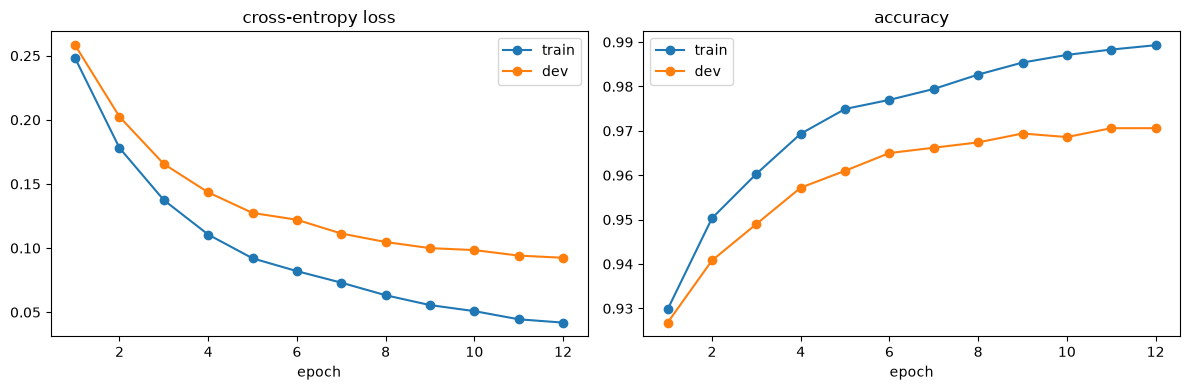

In [119]:
epochs_axis = np.arange(1, len(history["train_loss"]) + 1)

fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4))

ax_loss.plot(epochs_axis, history["train_loss"], marker="o", label="train")
ax_loss.plot(epochs_axis, history["dev_loss"], marker="o", label="dev")
ax_loss.set_title("cross-entropy loss")
ax_loss.set_xlabel("epoch")
ax_loss.legend()

ax_acc.plot(epochs_axis, history["train_acc"], marker="o", label="train")
ax_acc.plot(epochs_axis, history["dev_acc"], marker="o", label="dev")
ax_acc.set_title("accuracy")
ax_acc.set_xlabel("epoch")
ax_acc.legend()

# a growing gap between train and dev means overfitting
plt.tight_layout()
plt.show()

# confusion matrix (dev set)

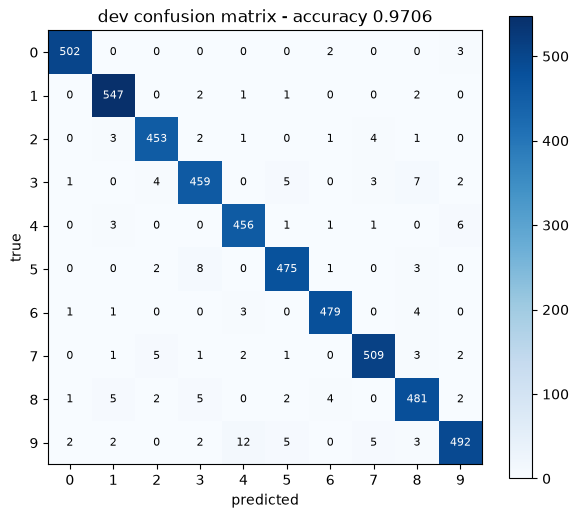

In [120]:
# this shows what the model picks vs the labels
# the diagonal line in dark blue shoes the correct prediction
# x axis is the prediction
# y axis is the label/truth

_, _, _, A2_dev = forward_pass(W1, b1, W2, b2, X_dev)
dev_pred = get_predictions(A2_dev)
dev_true = np.argmax(Y_dev, axis=0)

# rows = true digit, columns = predicted digit
cm = np.zeros((10, 10), dtype=int)
np.add.at(cm, (dev_true, dev_pred), 1)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues")
fig.colorbar(im, ax=ax)
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=8)
ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.set_title(f"dev confusion matrix - accuracy {np.mean(dev_pred == dev_true):.4f}")
plt.show()

# misclassified examples (most confident mistakes first)

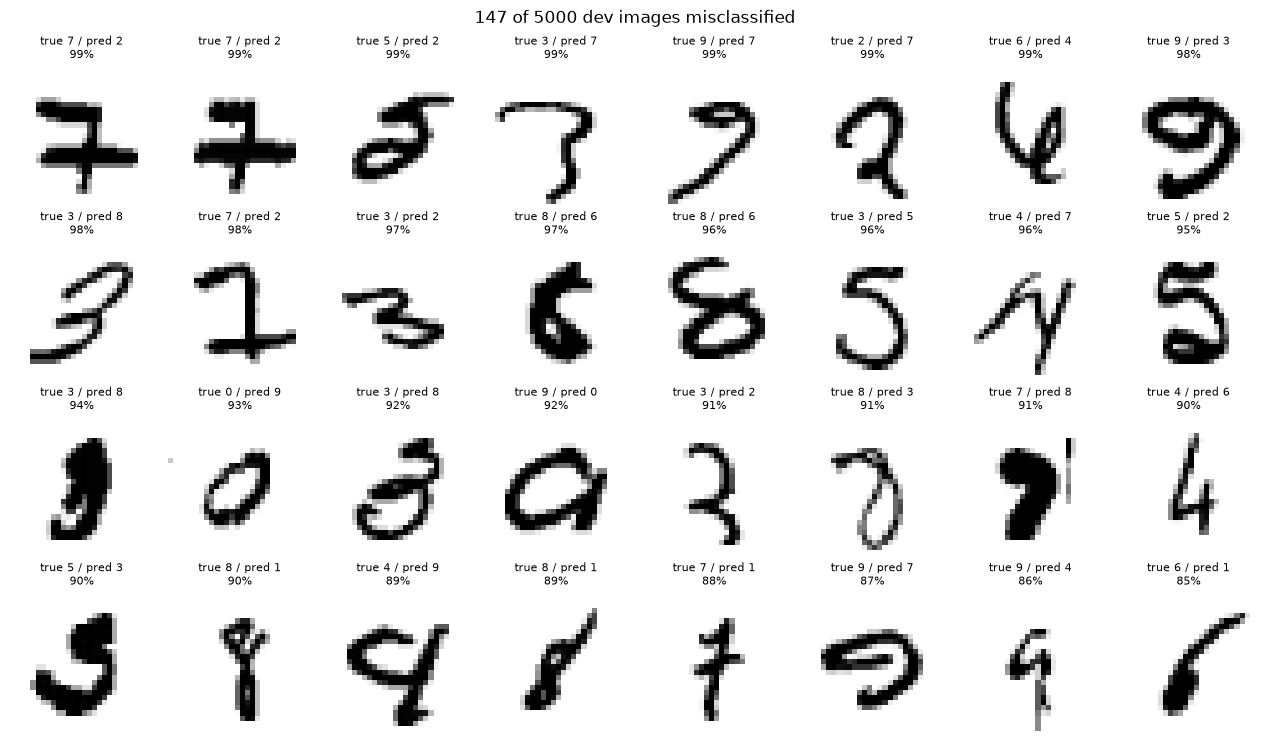

In [121]:
wrong = np.flatnonzero(dev_pred != dev_true)
confidence = A2_dev[dev_pred[wrong], wrong]       # probability given to the wrong answer
wrong = wrong[np.argsort(-confidence)]

rows, cols = 4, 8
fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.6, rows * 1.9))
for ax, idx in zip(axes.flat, wrong):
    ax.imshow(X_dev[:, idx].reshape(28, 28), cmap="gray_r")
    ax.set_title(f"true {dev_true[idx]} / pred {dev_pred[idx]}\n{A2_dev[dev_pred[idx], idx]:.0%}",
                 fontsize=8)
for ax in axes.flat:
    ax.axis("off")
fig.suptitle(f"{len(wrong)} of {len(dev_true)} dev images misclassified")
plt.tight_layout()
plt.show()